# Lab 6: Density-Based Clustering (DBSCAN)

### Objectives:
 1. Load and preprocess customer data for unsupervised learning.
 2. Apply a Standard Scaler to normalize feature distances.
 3. Perform K-Means clustering as a baseline comparison.
 4. Apply DBSCAN clustering to identify dense customer segments and isolate outliers i.e. noise.
 5. Visualize and compare the results of both clustering algorithms.

In [25]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans, DBSCAN
from sklearn.preprocessing import StandardScaler

df =pd.read_csv("/content/Mall_Customers (1).csv")

In [20]:
X = df[['Annual_Income_(k$)','Spending_Score']]
scaler= StandardScaler()
X_scaled= scaler.fit_transform(X)

### Algorithm Comparison
* **Standard K-Means:** Forces data into 5 clusters using random initial starting points.
* **K-Means++:** Improves upon standard K-Means by selecting smartly by choosing widely spaced starting points for more accurate grouping.
* **DBSCAN:** Auto-detects dense areas without a fixed cluster count (using `eps` and `min_samples`) and isolates scattered outliers as noise (`-1`).

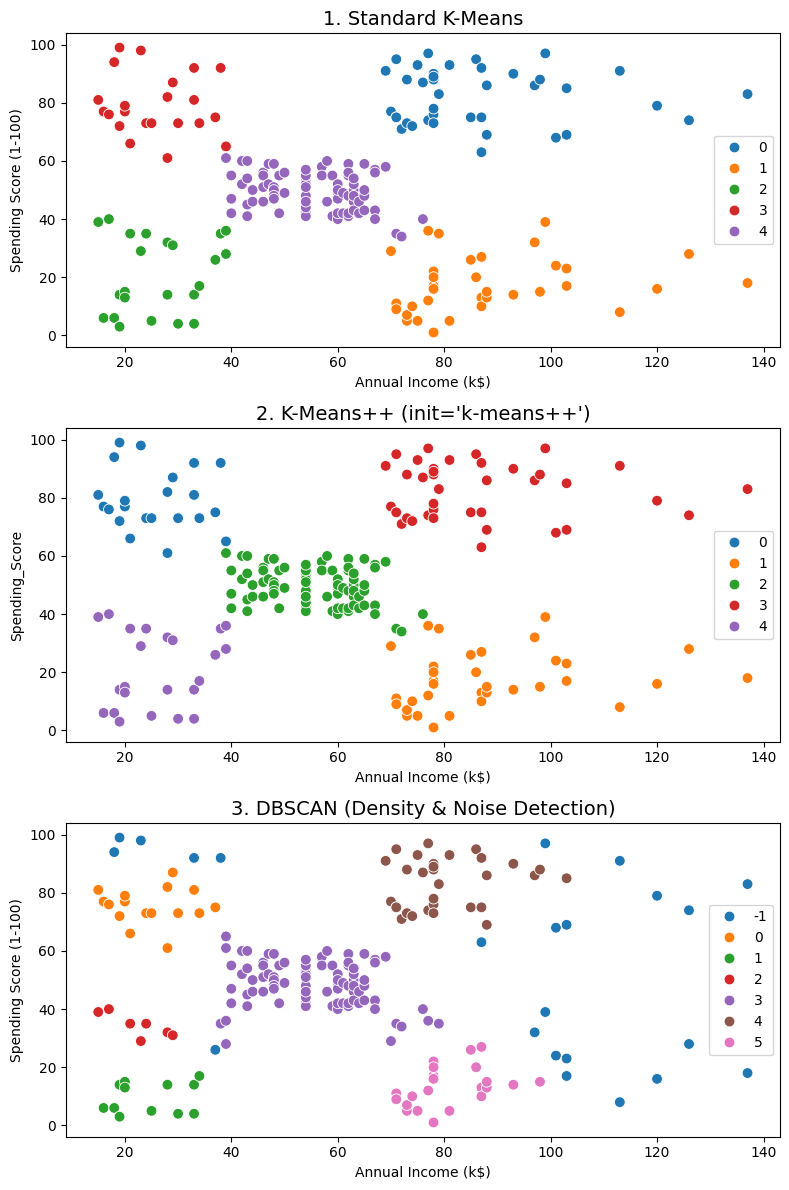

In [27]:
# K-Means Clustering
kmeans_r = KMeans(n_clusters=5, init='random', random_state=7, n_init=10)
r_labels = kmeans_r.fit_predict(X_scaled)

# K-Means++ Clustering
kmeans = KMeans(n_clusters=5, init='k-means++', random_state=7, n_init=10)
kmeans_labels = kmeans.fit_predict(X_scaled)

# DBSCAN Clustering
dbscan = DBSCAN(eps=0.35, min_samples=5)
dbscan_labels = dbscan.fit_predict(X_scaled)

fig, axes = plt.subplots(3, 1, figsize=(8, 12))
sns.scatterplot(x=X['Annual_Income_(k$)'], y=X['Spending_Score'],
                hue=r_labels, palette='tab10', ax=axes[0], s=60, legend='full')
axes[0].set_title("1. Standard K-Means", fontsize=14)
axes[0].set_xlabel("Annual Income (k$)")
axes[0].set_ylabel("Spending Score (1-100)")

sns.scatterplot(x=X['Annual_Income_(k$)'], y=X['Spending_Score'],
                hue=kmeans_labels, palette='tab10', ax=axes[1], s=60, legend='full')
axes[1].set_title("2. K-Means++ (init='k-means++')", fontsize=14)
axes[1].set_xlabel("Annual Income (k$)")

sns.scatterplot(x=X['Annual_Income_(k$)'], y=X['Spending_Score'],
                hue=dbscan_labels, palette='tab10', ax=axes[2], s=60, legend='full')
axes[2].set_title("3. DBSCAN (Density & Noise Detection)", fontsize=14)
axes[2].set_xlabel("Annual Income (k$)")
axes[2].set_ylabel("Spending Score (1-100)")
plt.tight_layout()
plt.show()